AP24110010606

In [ ]:
!pip install numpy pandas matplotlib scikit-learn

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

wine = load_wine()

X = wine.data
y = wine.target

print("Original Dataset Shape:", X.shape)
print("Number of Features:", X.shape[1])
print("Number of Classes:", len(np.unique(y)))

Original Dataset Shape: (178, 13)
Number of Features: 13
Number of Classes: 3


In [ ]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Standardization Completed")
print("Scaled Dataset Shape:", X_scaled.shape)

Standardization Completed
Scaled Dataset Shape: (178, 13)


In [ ]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("Original Shape:", X.shape)
print("Reduced Shape:", X_pca.shape)

print("Explained Variance Ratio:")
print(pca.explained_variance_ratio_)

print("Total Variance Retained:")
print(pca.explained_variance_ratio_.sum() * 100)

Original Shape: (178, 13)
Reduced Shape: (178, 2)
Explained Variance Ratio:
[0.36198848 0.1920749 ]
Total Variance Retained:
55.40633835693526


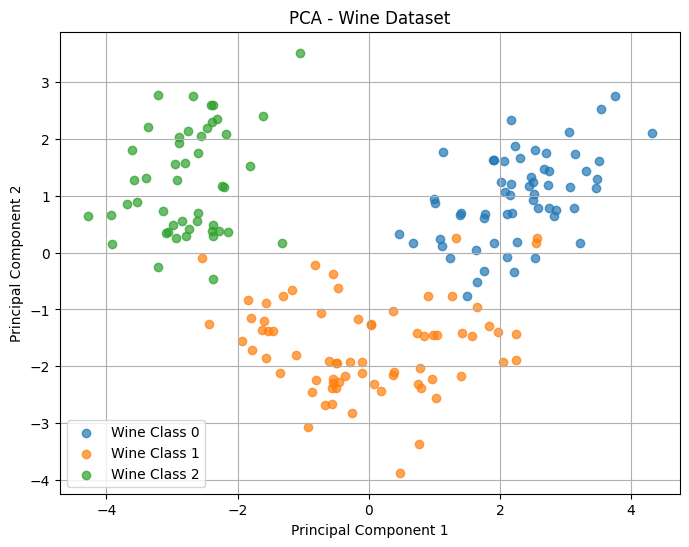

In [ ]:
plt.figure(figsize=(8, 6))

for i in np.unique(y):
    plt.scatter(
        X_pca[y == i, 0],
        X_pca[y == i, 1],
        label=f"Wine Class {i}",
        alpha=0.7
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA - Wine Dataset")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:

pca3 = PCA(n_components=3)
X_pca3 = pca3.fit_transform(X_scaled)

print("Reduced Shape:", X_pca3.shape)
print("Variance Retained:",
      pca3.explained_variance_ratio_.sum() * 100)


Reduced Shape: (178, 3)
Variance Retained: 66.52996889318523


In [ ]:

pca_raw = PCA(n_components=2)
X_raw = pca_raw.fit_transform(X)

print("Without Standardization:")
print(pca_raw.explained_variance_ratio_)

print("With Standardization:")
print(pca.explained_variance_ratio_)



Without Standardization:
[0.99809123 0.00173592]
With Standardization:
[0.36198848 0.1920749 ]


In [ ]:

for n in [1, 2, 3, 5, 10]:
    model = PCA(n_components=n)
    model.fit(X_scaled)

    variance = model.explained_variance_ratio_.sum() * 100
    print(f"{n} Components: {variance:.2f}%")

pca90 = PCA(n_components=0.90)
pca90.fit(X_scaled)

print("Components for 90% variance:",
      pca90.n_components_)


1 Components: 36.20%
2 Components: 55.41%
3 Components: 66.53%
5 Components: 80.16%
10 Components: 96.17%
Components for 90% variance: 8


In [ ]:

print("Original Features:")
print(wine.feature_names)

print("\nNew PCA Features:")
print(["PC1", "PC2"])

print("\nPCA Component Shape:")
print(pca.components_.shape)



Original Features:
['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']

New PCA Features:
['PC1', 'PC2']

PCA Component Shape:
(2, 13)


In [ ]:
reduced_df = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"]
)

reduced_df["Class"] = y

reduced_df.to_csv("PCA_Reduced_Wine.csv", index=False)

from google.colab import files
files.download("PCA_Reduced_Wine.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Load Wine Dataset
wine = load_wine()
X = wine.data
y = wine.target

# Standardize Features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply PCA: 13 features to 2
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("Original Dataset Shape:", X.shape)
print("Reduced Dataset Shape:", X_pca.shape)
print("Explained Variance Ratio:", pca.explained_variance_ratio_)
print("Total Variance Retained:",
      round(sum(pca.explained_variance_ratio_) * 100, 2), "%")


Original Dataset Shape: (178, 13)
Reduced Dataset Shape: (178, 2)
Explained Variance Ratio: [0.36198848 0.1920749 ]
Total Variance Retained: 55.41 %


1a

In [ ]:

pca3 = PCA(n_components=3)
X_pca3 = pca3.fit_transform(X_scaled)

print("Original Features:", X.shape[1])
print("Reduced Features:", X_pca3.shape[1])
print("Reduced Dataset Shape:", X_pca3.shape)


Original Features: 13
Reduced Features: 3
Reduced Dataset Shape: (178, 3)


1b

In [ ]:

print("Samples Before PCA:", X.shape[0])
print("Samples After PCA:", X_pca3.shape[0])

if X.shape[0] == X_pca3.shape[0]:
    print("Number of samples remains unchanged.")
else:
    print("Number of samples changed.")


Samples Before PCA: 178
Samples After PCA: 178
Number of samples remains unchanged.


1c

In [ ]:

variance2 = pca.explained_variance_ratio_.sum() * 100
variance3 = pca3.explained_variance_ratio_.sum() * 100

print("Variance with 2 Components:", round(variance2, 2), "%")
print("Variance with 3 Components:", round(variance3, 2), "%")

if variance3 > variance2:
    print("Total variance retained increases.")
else:
    print("Total variance does not increase.")


Variance with 2 Components: 55.41 %
Variance with 3 Components: 66.53 %
Total variance retained increases.


2a

In [ ]:

# PCA without standardization
pca_raw = PCA(n_components=2)
X_raw_pca = pca_raw.fit_transform(X)

print("With Standardization:")
print(pca.explained_variance_ratio_)

print("\nWithout Standardization:")
print(pca_raw.explained_variance_ratio_)

print("\nExplained variance ratios change:",
      not np.allclose(
          pca.explained_variance_ratio_,
          pca_raw.explained_variance_ratio_
      ))


With Standardization:
[0.36198848 0.1920749 ]

Without Standardization:
[0.99809123 0.00173592]

Explained variance ratios change: True


2b

In [ ]:

feature_variance = pd.DataFrame({
    "Feature": wine.feature_names,
    "Original Variance": np.var(X, axis=0),
    "Scaled Variance": np.var(X_scaled, axis=0)
})

feature_variance = feature_variance.sort_values(
    by="Original Variance",
    ascending=False
)

print(feature_variance.to_string(index=False))


                     Feature  Original Variance  Scaled Variance
                     proline       98609.600966              1.0
                   magnesium         202.843328              1.0
           alcalinity_of_ash          11.090031              1.0
             color_intensity           5.344256              1.0
                  malic_acid           1.241004              1.0
                  flavanoids           0.992114              1.0
                     alcohol           0.655360              1.0
od280/od315_of_diluted_wines           0.501254              1.0
               total_phenols           0.389489              1.0
             proanthocyanins           0.325754              1.0
                         ash           0.074842              1.0
                         hue           0.051951              1.0
        nonflavanoid_phenols           0.015402              1.0


2c

In [ ]:

pca_scaled = PCA(n_components=2)
pca_scaled.fit(X_scaled)

pca_unscaled = PCA(n_components=2)
pca_unscaled.fit(X)

print("With Standardization:")
print("Variance Retained:",
      round(pca_scaled.explained_variance_ratio_.sum() * 100, 2), "%")

print("\nWithout Standardization:")
print("Variance Retained:",
      round(pca_unscaled.explained_variance_ratio_.sum() * 100, 2), "%")

print("\nStandardization is recommended when")
print("features have different numerical scales.")


With Standardization:
Variance Retained: 55.41 %

Without Standardization:
Variance Retained: 99.98 %

Standardization is recommended when
features have different numerical scales.


3a

1 Components: 36.20%
2 Components: 55.41%
3 Components: 66.53%
5 Components: 80.16%
10 Components: 96.17%


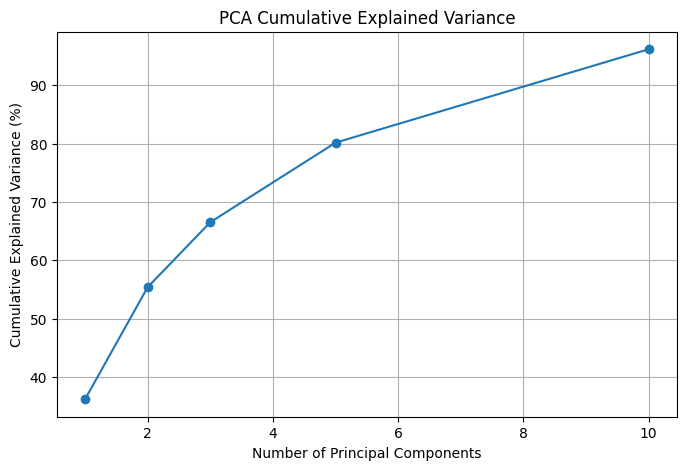

In [ ]:

components = [1, 2, 3, 5, 10]
variance_values = []

for n in components:
    pca_test = PCA(n_components=n)
    pca_test.fit(X_scaled)

    variance = pca_test.explained_variance_ratio_.sum() * 100
    variance_values.append(variance)

    print(f"{n} Components: {variance:.2f}%")

plt.figure(figsize=(8, 5))
plt.plot(components, variance_values, marker="o")

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance (%)")
plt.title("PCA Cumulative Explained Variance")
plt.grid(True)
plt.show()


3b

In [ ]:

pca90 = PCA(n_components=0.90)
X_pca90 = pca90.fit_transform(X_scaled)

print("Original Features:", X.shape[1])
print("Components Needed for 90% Variance:",
      pca90.n_components_)

print("Actual Variance Retained:",
      round(pca90.explained_variance_ratio_.sum() * 100, 2), "%")


Original Features: 13
Components Needed for 90% Variance: 8
Actual Variance Retained: 92.02 %


3c

In [ ]:

for n in [2, 5, 8, 10]:
    model = PCA(n_components=n)
    model.fit(X_scaled)

    retained = model.explained_variance_ratio_.sum() * 100
    lost = 100 - retained

    print(f"\nComponents: {n}")
    print(f"Variance Retained: {retained:.2f}%")
    print(f"Variance Lost: {lost:.2f}%")



Components: 2
Variance Retained: 55.41%
Variance Lost: 44.59%

Components: 5
Variance Retained: 80.16%
Variance Lost: 19.84%

Components: 8
Variance Retained: 92.02%
Variance Lost: 7.98%

Components: 10
Variance Retained: 96.17%
Variance Lost: 3.83%


4a

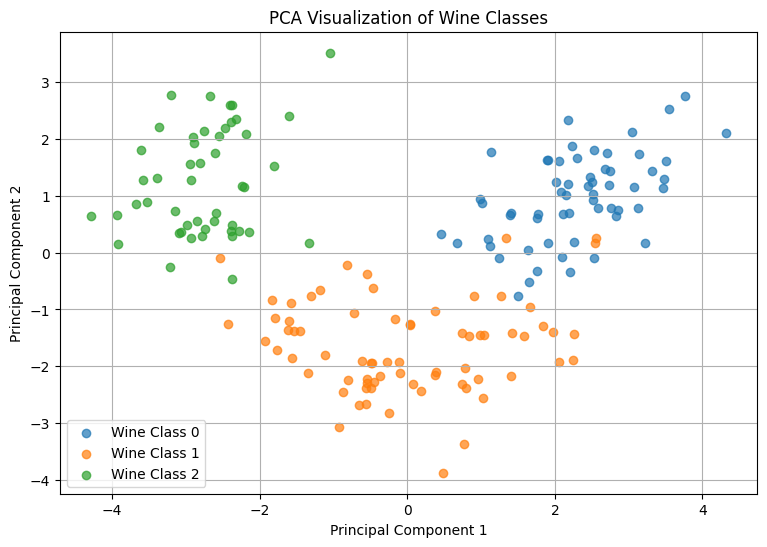

In [ ]:

plt.figure(figsize=(9, 6))

for i in np.unique(y):
    plt.scatter(
        X_pca[y == i, 0],
        X_pca[y == i, 1],
        label=f"Wine Class {i}",
        alpha=0.7
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization of Wine Classes")
plt.legend()
plt.grid(True)
plt.show()


4b

In [ ]:

total_variance = pca.explained_variance_ratio_.sum() * 100
variance_lost = 100 - total_variance

print("Original Features:", X.shape[1])
print("Reduced Features:", X_pca.shape[1])

print("Variance Retained:", round(total_variance, 2), "%")
print("Variance Lost:", round(variance_lost, 2), "%")


Original Features: 13
Reduced Features: 2
Variance Retained: 55.41 %
Variance Lost: 44.59 %


4c

In [ ]:

# PCA uses only feature data, not class labels
pca_no_labels = PCA(n_components=2)
X_result = pca_no_labels.fit_transform(X_scaled)

print("Input Features Shape:", X_scaled.shape)
print("Class Labels Shape:", y.shape)
print("PCA Output Shape:", X_result.shape)

print("\nPCA was fitted using X_scaled only.")
print("Class labels (y) were not used.")


Input Features Shape: (178, 13)
Class Labels Shape: (178,)
PCA Output Shape: (178, 2)

PCA was fitted using X_scaled only.
Class labels (y) were not used.


5a

In [ ]:

print("Original Wine Features:")
print(wine.feature_names)

print("\nNew PCA Features:")
print(["PC1", "PC2"])

print("\nFirst 5 Rows of PCA Dataset:")
df_pca = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
print(df_pca.head())


Original Wine Features:
['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']

New PCA Features:
['PC1', 'PC2']

First 5 Rows of PCA Dataset:
        PC1       PC2
0  3.316751  1.443463
1  2.209465 -0.333393
2  2.516740  1.031151
3  3.757066  2.756372
4  1.008908  0.869831


5b

In [ ]:

# Feature Selection: Keep 2 existing columns
X_selected = X[:, :2]

# Feature Extraction: Create 2 new PCA features
pca_extract = PCA(n_components=2)
X_extracted = pca_extract.fit_transform(X_scaled)

print("Feature Selection Shape:", X_selected.shape)
print("Feature Extraction Shape:", X_extracted.shape)

print("\nSelected Original Features:")
print(wine.feature_names[:2])

print("\nExtracted Features:")
print(["PC1", "PC2"])

print("\nFeature Selection Example:")
print(X_selected[:3])

print("\nFeature Extraction Example:")
print(X_extracted[:3])


Feature Selection Shape: (178, 2)
Feature Extraction Shape: (178, 2)

Selected Original Features:
['alcohol', 'malic_acid']

Extracted Features:
['PC1', 'PC2']

Feature Selection Example:
[[14.23  1.71]
 [13.2   1.78]
 [13.16  2.36]]

Feature Extraction Example:
[[ 3.31675081  1.44346263]
 [ 2.20946492 -0.33339289]
 [ 2.51674015  1.0311513 ]]


5c

In [ ]:

pca_final = PCA(n_components=2)
X_final = pca_final.fit_transform(X_scaled)

print("Original Number of Features:", X.shape[1])
print("Extracted Number of Features:", X_final.shape[1])

print("\nPCA Component Matrix Shape:")
print(pca_final.components_.shape)

print("\nPCA Component Weights:")
print(pd.DataFrame(
    pca_final.components_,
    columns=wine.feature_names,
    index=["PC1", "PC2"]
).round(3))

print("\nPCA creates new features using")
print("linear combinations of original features.")


Original Number of Features: 13
Extracted Number of Features: 2

PCA Component Matrix Shape:
(2, 13)

PCA Component Weights:
     alcohol  malic_acid    ash  alcalinity_of_ash  magnesium  total_phenols  \
PC1    0.144      -0.245 -0.002             -0.239      0.142          0.395   
PC2    0.484       0.225  0.316             -0.011      0.300          0.065   

     flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity  \
PC1       0.423                -0.299            0.313           -0.089   
PC2      -0.003                 0.029            0.039            0.530   

       hue  od280/od315_of_diluted_wines  proline  
PC1  0.297                         0.376    0.287  
PC2 -0.279                        -0.164    0.365  

PCA creates new features using
linear combinations of original features.
